# Relational Database Foundations

A **relational database** stores data in **tables** (relations). Tables are linked by **keys**. The database enforces rules (**constraints**) so that the data stays consistent. This design, proposed by Edgar F. Codd in 1970, still runs most business systems.

**After this lesson you can:**

1. Explain tables, rows, columns, primary keys and foreign keys.
2. Read an entity-relationship structure from a real database.
3. See how constraints protect data integrity.
4. Explain normalisation and why it avoids update anomalies.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads and loads the sample data

engine = create_engine(datasets.ensure_chinook())  # starts PostgreSQL in Docker and loads Chinook on first use

def q(sql: str, **params) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

## 1. Tables, Rows and Columns

| Term | Meaning | Chinook example |
| :--- | :--- | :--- |
| **table** | one kind of thing | `customer`, `invoice`, `track` |
| **row** (record, tuple) | one instance | the customer with id 5 |
| **column** (attribute) | one property, with a data type | `country VARCHAR(40)` |
| **primary key (PK)** | column(s) that identify each row uniquely | `customer.customer_id` |
| **foreign key (FK)** | column that refers to a PK in another table | `invoice.customer_id` → `customer` |

In [2]:
q("SELECT customer_id, first_name, last_name, city, country, support_rep_id FROM customer ORDER BY customer_id LIMIT 5")

,customer_id,first_name,last_name,city,country,support_rep_id
0,1,Luís,Gonçalves,São José dos Campos,Brazil,3
1,2,Leonie,Köhler,Stuttgart,Germany,5
2,3,François,Tremblay,Montréal,Canada,3
3,4,Bjørn,Hansen,Oslo,Norway,4
4,5,František,Wichterlová,Prague,Czech Republic,4


## 2. Keys and Relationships

The system catalog lists every foreign key. Each one is a relationship: a **one-to-many** link from the referenced table (one) to the referencing table (many). The link table `playlist_track` implements a **many-to-many** relationship between playlists and tracks.

In [3]:
fks = q("""
    SELECT tc.table_name AS child_table, kcu.column_name AS fk_column,
           ccu.table_name AS parent_table, ccu.column_name AS parent_key
    FROM information_schema.table_constraints tc
    JOIN information_schema.key_column_usage kcu ON tc.constraint_name = kcu.constraint_name
    JOIN information_schema.constraint_column_usage ccu ON tc.constraint_name = ccu.constraint_name
    WHERE tc.constraint_type = 'FOREIGN KEY'
    ORDER BY child_table
""")
fks

,child_table,fk_column,parent_table,parent_key
0,album,artist_id,artist,artist_id
1,customer,support_rep_id,employee,employee_id
2,employee,reports_to,employee,employee_id
3,invoice,customer_id,customer,customer_id
4,invoice_line,invoice_id,invoice,invoice_id
5,invoice_line,track_id,track,track_id
6,playlist_track,playlist_id,playlist,playlist_id
7,playlist_track,track_id,track,track_id
8,track,album_id,album,album_id
9,track,genre_id,genre,genre_id


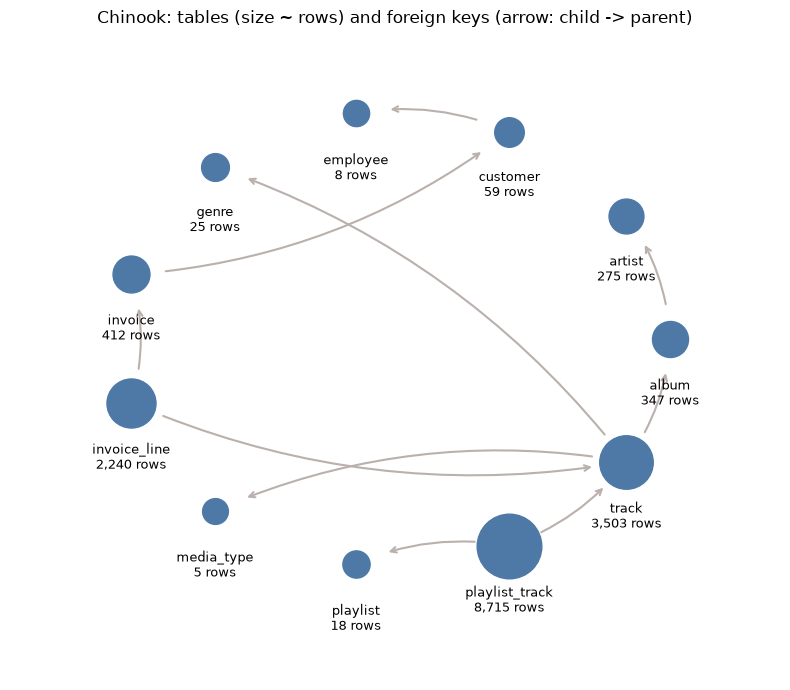

In [4]:
import math

tables = sorted(set(fks["child_table"]) | set(fks["parent_table"]))
pos = {t: (math.cos(2 * math.pi * i / len(tables)), math.sin(2 * math.pi * i / len(tables))) for i, t in enumerate(tables)}
rows = {t: q(f"SELECT count(*) AS n FROM {t}")["n"][0] for t in tables}

fig, ax = plt.subplots(figsize=(8, 7))
for _, r in fks.iterrows():
    (x1, y1), (x2, y2) = pos[r["child_table"]], pos[r["parent_table"]]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color="#BAB0AC", lw=1.5, shrinkA=25, shrinkB=25,
                                connectionstyle="arc3,rad=0.15" if r["child_table"] != r["parent_table"] else "arc3,rad=1.2"))
for t, (x, y) in pos.items():
    ax.scatter(x, y, s=300 + 20 * math.sqrt(rows[t]), color="#4E79A7", zorder=3)
    ax.text(x, y - 0.17, f"{t}\n{rows[t]:,} rows", ha="center", va="top", fontsize=9)
ax.set(title="Chinook: tables (size ~ rows) and foreign keys (arrow: child -> parent)", xlim=(-1.4, 1.4), ylim=(-1.5, 1.35))
ax.axis("off")
plt.tight_layout()
plt.show()

`employee.reports_to` refers to `employee` itself: a **self-referencing** key that models the management hierarchy. `customer.support_rep_id` links each customer to the employee who supports them.

## 3. Constraints Protect the Data

| Constraint | Rule |
| :--- | :--- |
| `PRIMARY KEY` | unique and not null |
| `FOREIGN KEY` | the value must exist in the parent table |
| `NOT NULL` | a value is required |
| `UNIQUE` | no duplicates |
| `CHECK (expr)` | a custom rule, e.g. `CHECK (quantity > 0)` |

The database rejects every change that breaks a constraint. The cell tries three invalid inserts in a transaction that is always rolled back, so Chinook stays unchanged.

In [5]:
attempts = {
    "duplicate primary key": "INSERT INTO genre (genre_id, name) VALUES (1, 'Duplicate')",
    "unknown foreign key": "INSERT INTO invoice (invoice_id, customer_id, invoice_date, total) VALUES (9999, 424242, now(), 1)",
    "missing required value": "INSERT INTO artist (artist_id, name) VALUES (NULL, 'Nobody')",
}
for name, sql in attempts.items():
    with engine.connect() as conn:
        trans = conn.begin()
        try:
            conn.execute(text(sql))
            print(f"{name:<24} accepted (unexpected)")
        except Exception as err:
            print(f"{name:<24} rejected: {str(err.orig).splitlines()[0]}")
        finally:
            trans.rollback()

duplicate primary key    rejected: duplicate key value violates unique constraint "genre_pkey"
unknown foreign key      rejected: insert or update on table "invoice" violates foreign key constraint "invoice_customer_id_fkey"
missing required value   rejected: null value in column "artist_id" of relation "artist" violates not-null constraint


## 4. Normalisation

**Normalisation** organises columns so that each fact is stored in **one place**. Without it, the same fact is copied into many rows, and updates create **anomalies**: you change it in one row and forget the others.

| Normal form | Rule (simplified) |
| :--- | :--- |
| **1NF** | every cell holds one value (no lists in a cell) |
| **2NF** | every non-key column depends on the **whole** primary key |
| **3NF** | non-key columns depend **only** on the key, not on other non-key columns |

The cell builds a **denormalised** table (one wide row per invoice line) from the normalised tables and measures how often facts repeat.

In [6]:
wide = q("""
    SELECT il.invoice_line_id, i.invoice_id, i.invoice_date, c.first_name || ' ' || c.last_name AS customer,
           c.email, c.country, t.name AS track, ar.name AS artist, g.name AS genre, il.unit_price, il.quantity
    FROM invoice_line il
    JOIN invoice i ON i.invoice_id = il.invoice_id
    JOIN customer c ON c.customer_id = i.customer_id
    JOIN track t ON t.track_id = il.track_id
    JOIN album al ON al.album_id = t.album_id
    JOIN artist ar ON ar.artist_id = al.artist_id
    JOIN genre g ON g.genre_id = t.genre_id
""")
copies = {col: len(wide) / wide[col].nunique() for col in ["email", "artist", "genre", "country"]}
print(f"denormalised table: {len(wide):,} rows x {wide.shape[1]} columns")
for col, k in copies.items():
    print(f"  each {col:<8} value is stored {k:6.1f} times on average")
wide.head(3)

denormalised table: 2,240 rows x 11 columns
  each email    value is stored   38.0 times on average
  each artist   value is stored   13.6 times on average
  each genre    value is stored   93.3 times on average
  each country  value is stored   93.3 times on average


,invoice_line_id,invoice_id,invoice_date,customer,email,country,track,artist,genre,unit_price,quantity
0,1,1,2021-01-01,Leonie Köhler,leonekohler@surfeu.de,Germany,Balls to the Wall,Accept,Rock,0.99,1
1,2,1,2021-01-01,Leonie Köhler,leonekohler@surfeu.de,Germany,Restless and Wild,Accept,Rock,0.99,1
2,3,2,2021-01-02,Bjørn Hansen,bjorn.hansen@yahoo.no,Norway,Put The Finger On You,AC/DC,Rock,0.99,1


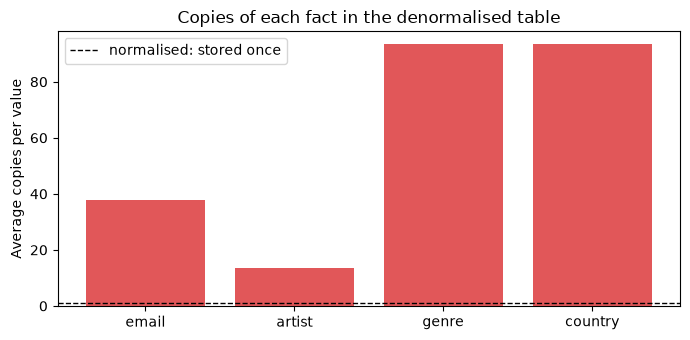

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(copies.keys(), copies.values(), color="#E15759")
ax.axhline(1, color="black", lw=1, ls="--", label="normalised: stored once")
ax.set(title="Copies of each fact in the denormalised table", ylabel="Average copies per value")
ax.legend()
plt.tight_layout()
plt.show()

In the wide table, a customer's e-mail address appears on every line they ever bought. If the customer changes the address, every copy must change. In the normalised schema, the address lives in exactly one row of `customer`.

Analytics systems sometimes **denormalise on purpose** to make queries simpler and faster (star schemas, Lesson 15). The source of truth stays normalised.

*Insight: Normalise the operational database so that each fact has one home and the database enforces the rules. Denormalise copies of the data for analytics, where reads are much more frequent than writes.*

## Real-World Use Case or Analogy

A normalised database is like a **well-run library catalogue**. Each author has one card with the biography; each book card refers to the author's card instead of copying the biography. When an author's details change, the librarian updates one card, and every book shows the new information.

Banks, airlines, shops and hospitals run on relational databases for this reason: foreign keys and constraints guarantee that an order cannot refer to a customer who does not exist, and a payment cannot have a negative amount.